# Rossmann Store Sales — 03 Promo and holiday effects
How much do promotions and holidays change daily sales? Three complementary estimates:

1. **Descriptive** comparisons (intuitive but confounded by weekday and season).
2. **Fixed-effects regression** (statsmodels OLS) of log sales with store fixed effects and calendar controls —
   the main causal-style estimate. Promo is set chain-wide on a fixed bi-weekly calendar (identical for all stores
   on a given date, not chosen by store managers), so promo weeks vs non-promo weeks with calendar controls is close to a natural experiment.
3. **Model-based**: counterfactual forecasts of the global LightGBM with the promo calendar switched off, and an
   ablation study (retraining without promo / holiday features).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from IPython.display import Image, display, Markdown
from rossmann import config, data, features as F, models as M, metrics as MET, effects as E, pipeline

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
MET_DIR, FIG_DIR = config.MET_DIR, config.FIG_DIR
print("repo:", ROOT.name)

repo: rossmann-sales-forecasting


In [2]:
panel = pd.read_parquet(config.DATA_DIR / "panel.parquet") if (config.DATA_DIR / "panel.parquet").exists() \
    else pipeline.prepare(config.RAW_DIR)[3]
known = panel[panel.is_test == 0]
summary = json.loads((config.OUT_DIR / "summary.json").read_text())   # results of run_pipeline.py
print(f"{len(known):,} store-days, {((known.Open == 1) & (known.Sales > 0)).sum():,} open days with sales")

1,017,209 store-days, 844,338 open days with sales


## 1. Descriptive view

In [3]:
desc = E.descriptive(known)
for k, v in desc.items():
    display(Markdown(f"**{k}**")); display(v.round(3))

**promo_overall**

Promo,no_promo,promo,uplift_pct
Sales,"5,929.8260","8,228.7400",38.7690
Customers,696.9060,844.4810,21.1760
SalesPerCustomer,8.9410,10.1790,13.8440


**promo_by_weekday**

Promo,no_promo,promo,uplift_pct
DayOfWeek,,,
1,"6,222.7280","9,772.9110",57.0520
2,"5,716.4120","8,277.6310",44.8050
3,"5,617.7290","7,685.6830",36.8110
4,"5,750.8830","7,598.7880",32.1330
5,"6,344.4120","7,744.3880",22.0660


**promo_by_storetype**

Promo,no_promo,promo,uplift_pct
StoreType,,,
a,"6,029.1670","8,304.5490",37.7400
b,"9,426.8110","11,311.8030",19.9960
c,"5,766.6890","8,042.7880",39.4700
d,"5,637.8520","8,018.0370",42.2180


**state_holiday**

,store_days,share_open,mean_sales_if_open
StateHoliday,,,
none,986159,0.8550,"6,953.9600"
public,20260,0.0340,"8,487.4710"
Easter,6690,0.0220,"9,887.8900"
Christmas,4100,0.0170,"9,743.7460"


**school_holiday**

,mean_sales,ratio
SchoolHoliday,,
0,"6,897.2080",1.0000
1,"7,200.7100",1.0440


Raw promo uplift is about +39 % on sales, and it is not spread evenly: it is far larger on Mondays than on Fridays. On state holidays only 2–3 % of stores
open, so holidays mainly act through **closures** and through shopping shifted to the days around them.

## 2. Fixed-effects regression
$$\log(\text{Sales}_{st}) = \alpha_s + \beta\,\text{Promo}_t + \gamma'\,\text{Holiday}_{st} + \delta'\,\text{Calendar}_t + \varepsilon_{st}$$

* $\alpha_s$: store fixed effect (within transformation: each variable is demeaned per store)
* Calendar controls: weekday, month, year and day-of-month dummies
* Holiday terms: 1–3 days before / after a state holiday (outside the Christmas window), open on a holiday,
  each day 18–24 Dec and 27–31 Dec, school holiday, reopening after a closure of ≥ 5 days
* Standard errors clustered two-way by store and by date (promo varies by date)
* Effect in % $= 100\,(e^{\beta}-1)$

In [4]:
tab, full, res = E.fe_ols(known)
print(tab.attrs)
tab[["effect_pct", "ci_low_pct", "ci_high_pct", "p"]].round(3)

{'n_obs': 844338, 'r2_within': 0.565311576646613, 'target': 'Sales', 'interactions': None}


,effect_pct,ci_low_pct,ci_high_pct,p
Promo,37.9410,36.2280,39.6760,0.0000
SchoolHoliday,1.1240,0.0800,2.1800,0.0350
Promo2 month,-0.2660,-0.6470,0.1150,0.1710
Open on state holiday,-9.9550,-22.3970,4.4830,0.1670
1 day(s) before holiday,19.3230,15.1290,23.6710,0.0000
1 day(s) after holiday,23.1170,19.6440,26.6920,0.0000
2 day(s) before holiday,7.1400,4.2910,10.0670,0.0000
2 day(s) after holiday,4.1980,1.5570,6.9080,0.0020
3 day(s) before holiday,1.3390,-1.9070,4.6920,0.4230
3 day(s) after holiday,6.2340,3.6540,8.8790,0.0000


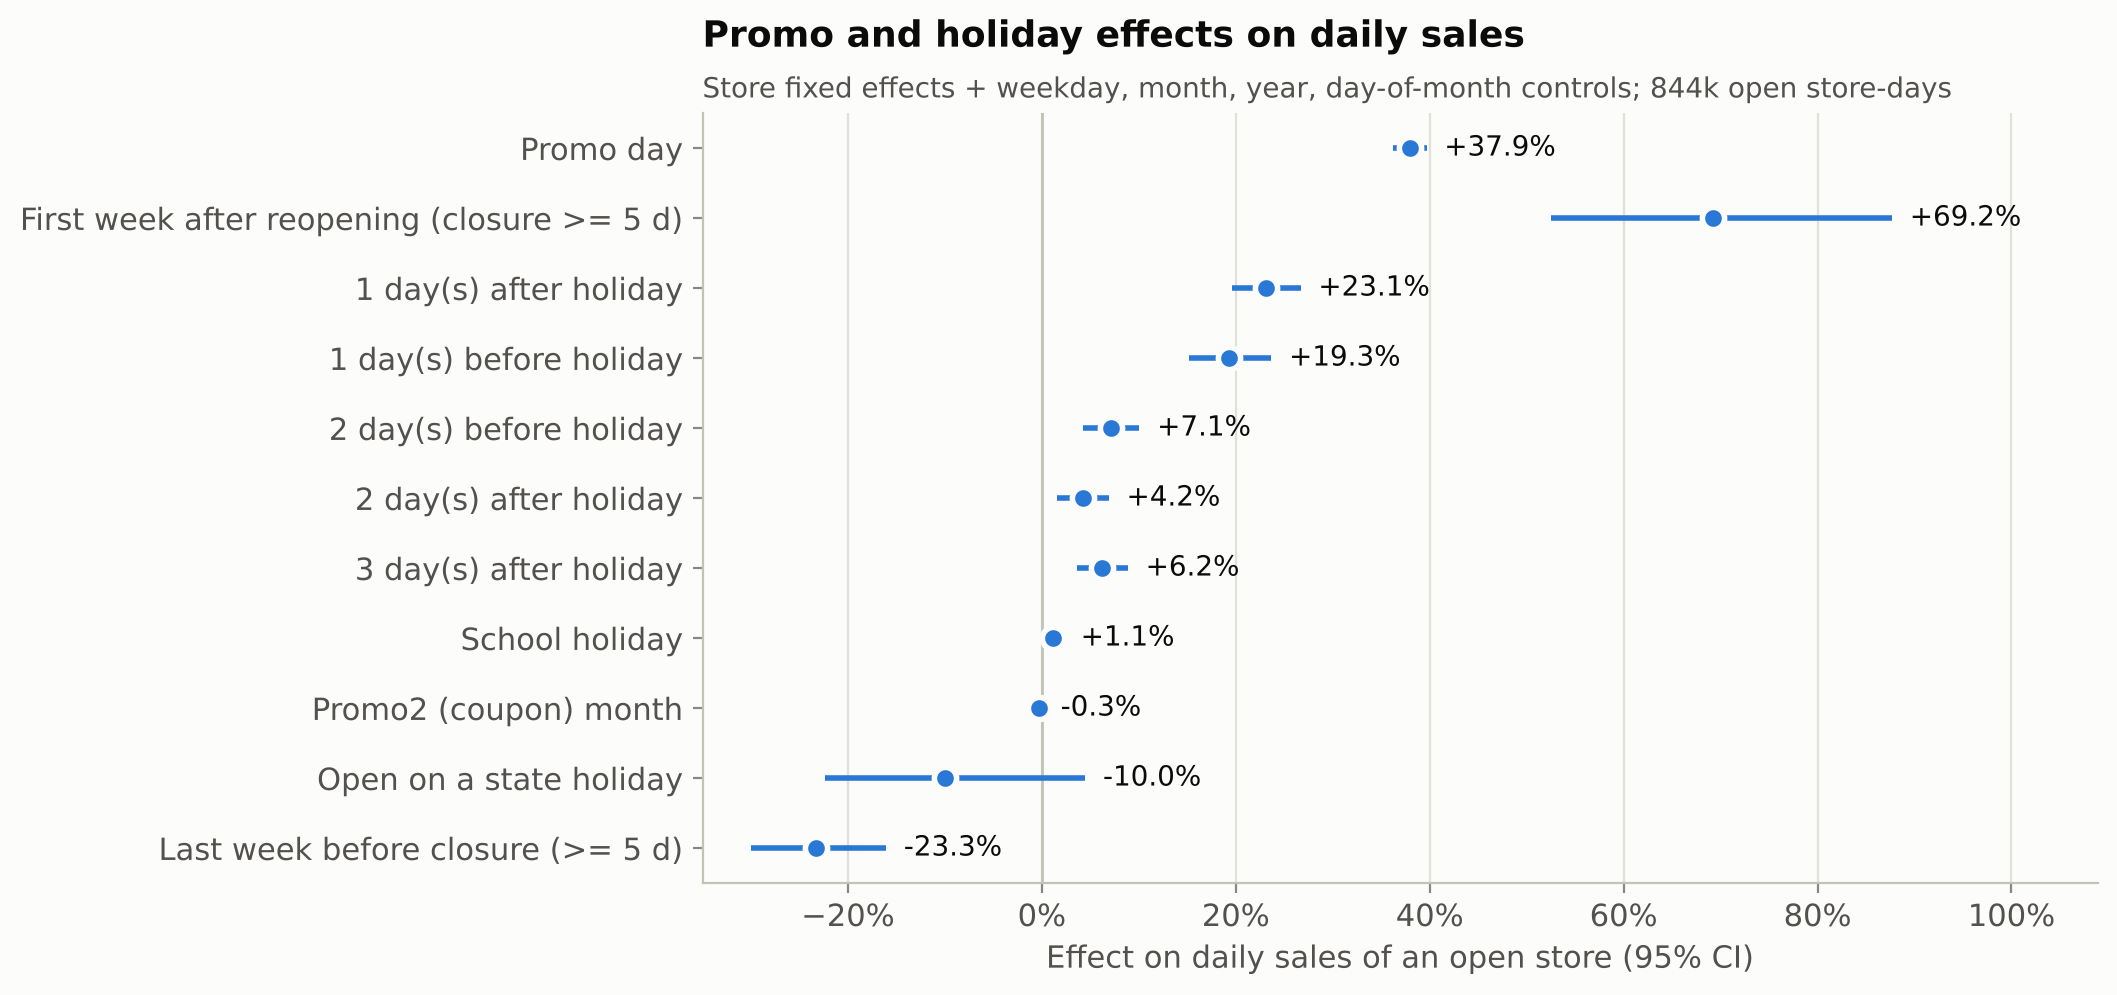

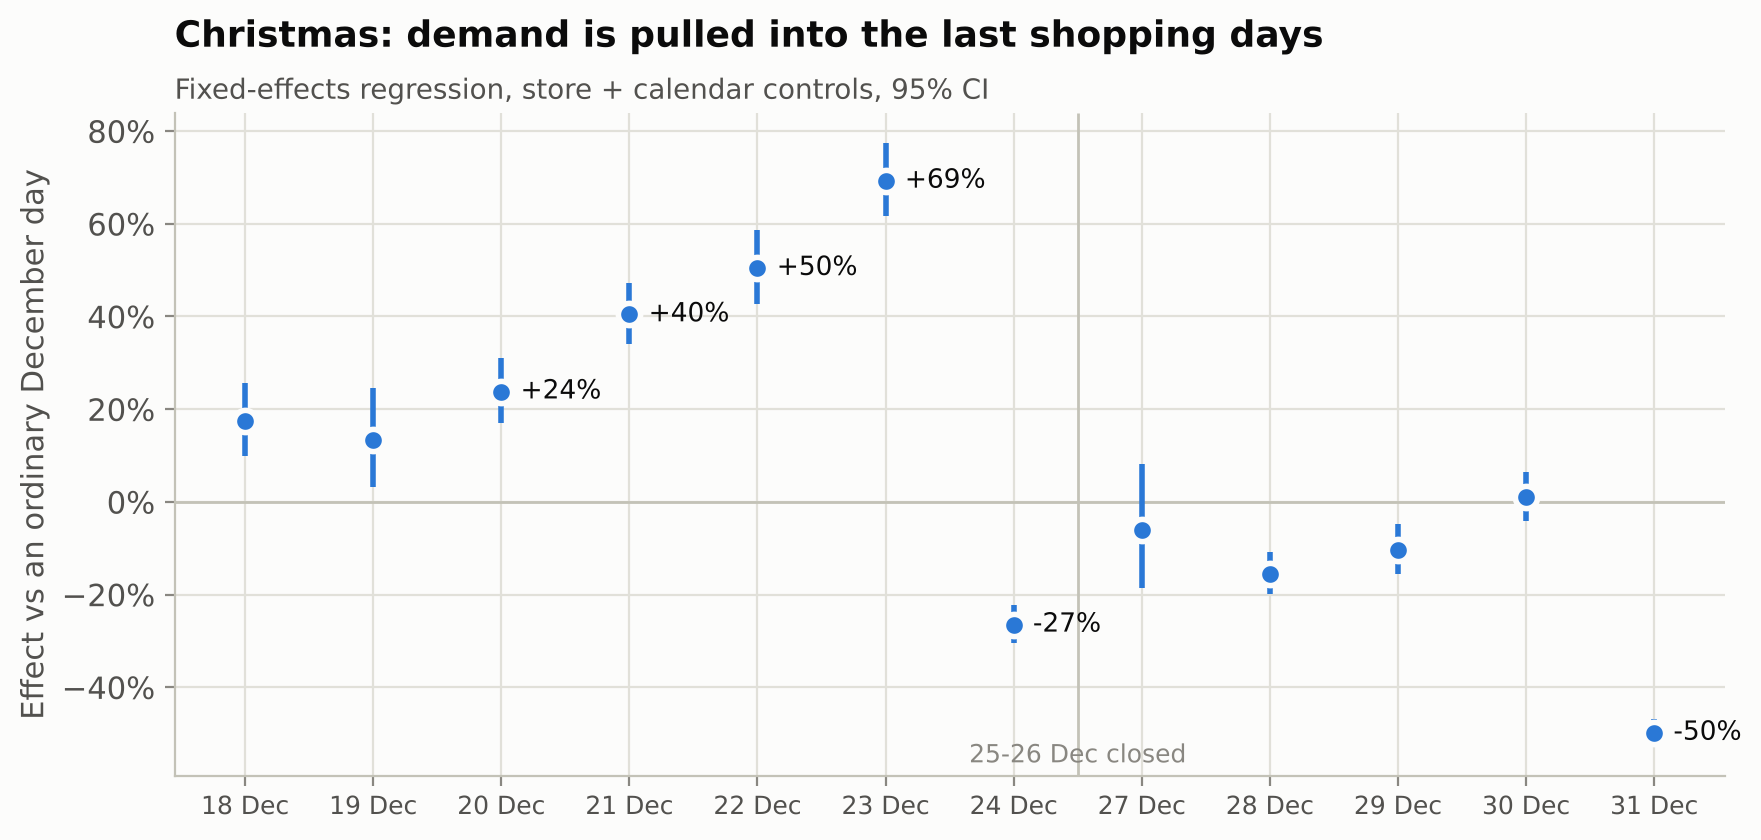

In [5]:
display(Image(FIG_DIR / "fig10_promo_holiday_effects.png", width=900))
display(Image(FIG_DIR / "fig11_christmas.png", width=900))

### Where does the promo uplift come from: more customers or bigger baskets?

,effect_pct,ci_low_pct,ci_high_pct
Sales,37.9400,36.2300,39.6800
Customers,20.0400,19.0100,21.0700
SalesPerCustomer,14.9100,14.3600,15.4800


check: (1 + customers) x (1 + basket) - 1 = 37.9%


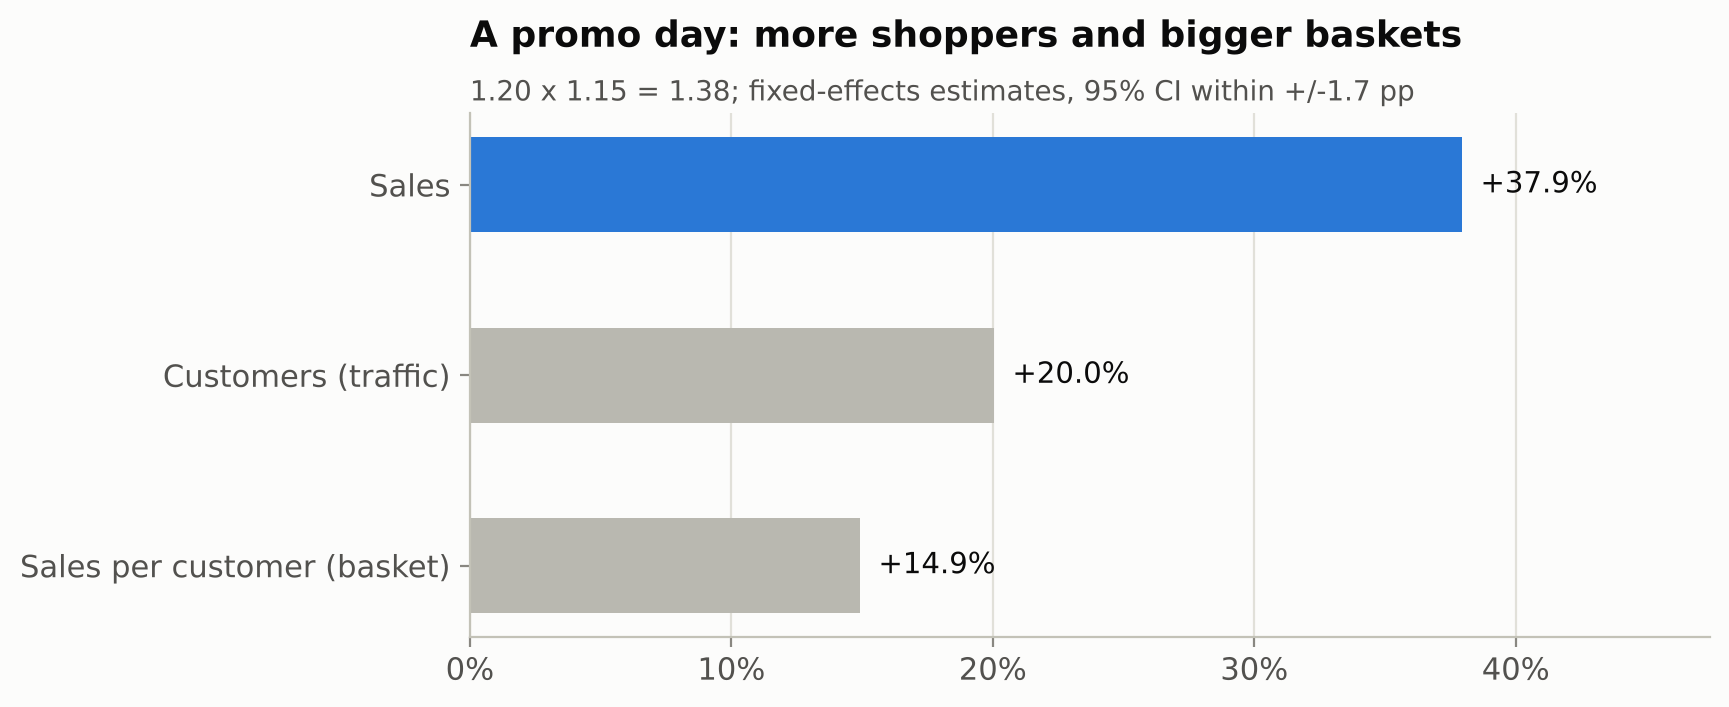

In [6]:
dec = {}
for tgt in ["Sales", "Customers", "SalesPerCustomer"]:
    t = tab if tgt == "Sales" else E.fe_ols(known, tgt)[0]
    dec[tgt] = t.loc["Promo", ["effect_pct", "ci_low_pct", "ci_high_pct"]]
dec = pd.DataFrame(dec).T
display(dec.round(2))
print(f"check: (1 + customers) x (1 + basket) - 1 = {((1 + dec.effect_pct.iloc[1] / 100) * (1 + dec.effect_pct.iloc[2] / 100) - 1) * 100:.1f}%")
display(Image(FIG_DIR / "fig13_promo_decomposition.png", width=700))

### Heterogeneity: weekday, store type, assortment

**Promo effect by weekday** (diff_p = p-value of the difference to the reference group)

,group,effect_pct,diff_p
0,1,61.5880,NaN
1,2,46.4290,0.0000
2,3,33.9760,0.0000
3,4,29.1600,0.0000
4,5,22.1350,0.0000


**Promo effect by storetype** (diff_p = p-value of the difference to the reference group)

,group,effect_pct,diff_p
0,a,42.5580,NaN
1,b,12.0800,0.0000
2,c,32.1180,0.0000
3,d,34.0760,0.0000


**Promo effect by assortment** (diff_p = p-value of the difference to the reference group)

,group,effect_pct,diff_p
0,a,42.5210,NaN
1,b,1.3460,0.0000
2,c,33.6470,0.0000


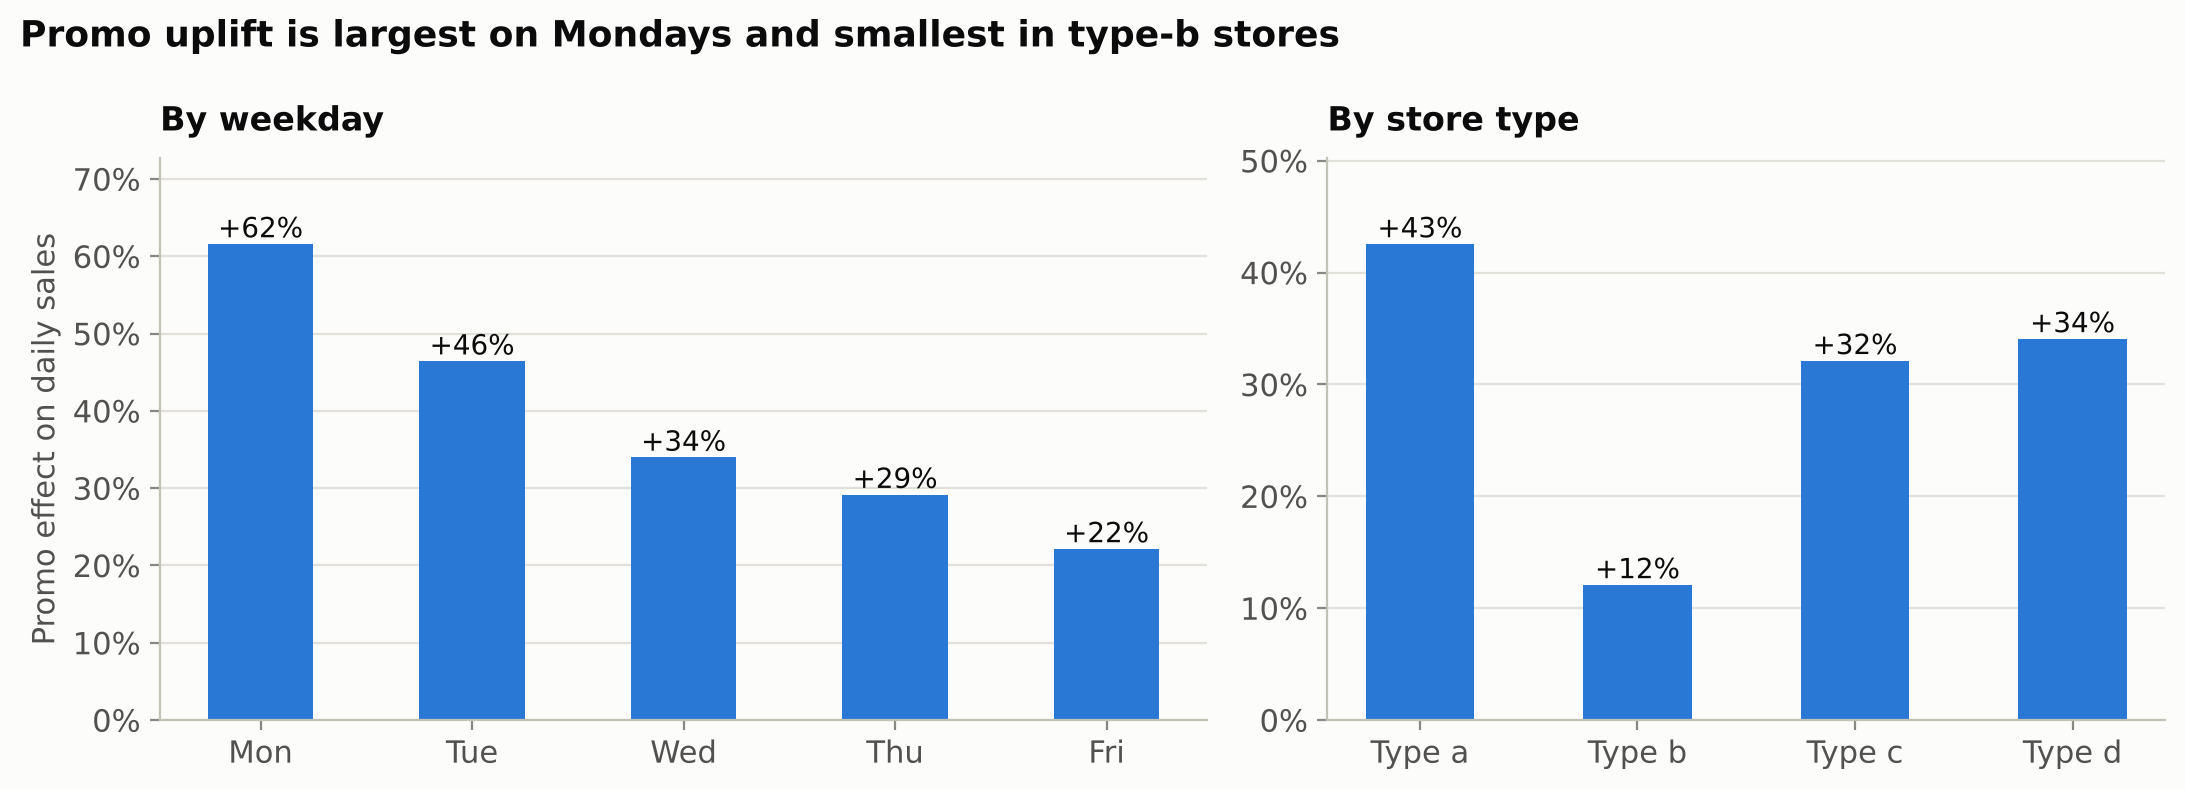

In [7]:
for inter, prefix, ref in [("weekday", "Promo x weekday ", "1"), ("storetype", "Promo x type ", "a"),
                           ("assortment", "Promo x assortment ", "a")]:
    _, f, _ = E.fe_ols(known, interactions=inter)
    display(Markdown(f"**Promo effect by {inter}** (diff_p = p-value of the difference to the reference group)"))
    display(E.interaction_effects(f, "Promo", prefix, ref).round(3))
display(Image(FIG_DIR / "fig12_promo_heterogeneity.png", width=900))

## 3. Model-based estimates (global LightGBM, hold-out F1)
A tree model cannot extrapolate, so a counterfactual must stay inside feature combinations seen in training. On real
non-promo weekdays the week before and after are promo weeks in 94% of cases; a day with no promo in the previous,
current and next week never occurs. The main scenario therefore turns each promo week into a *regular* week
(Promo = 0, promo in the neighbouring weeks); switching off only the promo flag is shown as a sensitivity check.

In [8]:
cf = summary["promo_counterfactual"]
print(f"Promo-day uplift, promo weeks turned into regular weeks (in-distribution): {cf['promo_day_uplift_pct']:+.1f}%")
print(f"Sensitivity, promo flag only switched off (feature combination never seen in training): {cf['promo_day_uplift_flag_only_pct']:+.1f}%")
print(f"Extra sales on promo days: EUR {cf['promo_days_incremental_eur'] / 1e6:,.1f}M = {cf['promo_days_incremental_share_pct']:.1f}% of hold-out sales")
display(pd.read_csv(MET_DIR / "promo_counterfactual_by_storetype.csv", index_col=0).round(1))
display(pd.read_csv(MET_DIR / "promo_counterfactual_by_weekday.csv", index_col=0).round(1))

Promo-day uplift, promo weeks turned into regular weeks (in-distribution): +36.8%
Sensitivity, promo flag only switched off (feature combination never seen in training): +24.1%
Extra sales on promo days: EUR 38.1M = 13.5% of hold-out sales


,with,without,uplift_pct
StoreType,,,
a,"75,851,640.4000","56,019,106.9000",35.4000
b,"3,013,181.4000","2,549,382.7000",18.2000
c,"18,437,930.0000","13,347,443.8000",38.1000
d,"44,227,051.4000","31,523,552.9000",40.3000


,with,without,uplift_pct
DayOfWeek,,,
1,"33,505,131.3000","21,470,712.6000",56.1000
2,"28,747,768.4000","20,318,109.6000",41.5000
3,"26,027,002.2000","19,810,658.7000",31.4000
4,"26,412,426.2000","20,281,339.5000",30.2000
5,"26,837,475.1000","21,558,665.8000",24.5000


### Ablation: how much forecast accuracy depends on promo and holiday information
Retrain the global model without each feature group and evaluate on fold F3 (28 Mar – 8 May 2015), the
backtest window that contains Easter and 1 May (F1 has no state holidays).

variant,Full model,Without holiday features,Without promo features
segment,,,
+/-3 days around a holiday,0.1107,0.1524,0.2196
All open days,0.0961,0.1166,0.1941
Non-promo days,0.0966,0.1203,0.2014
Promo days,0.0958,0.1133,0.1877


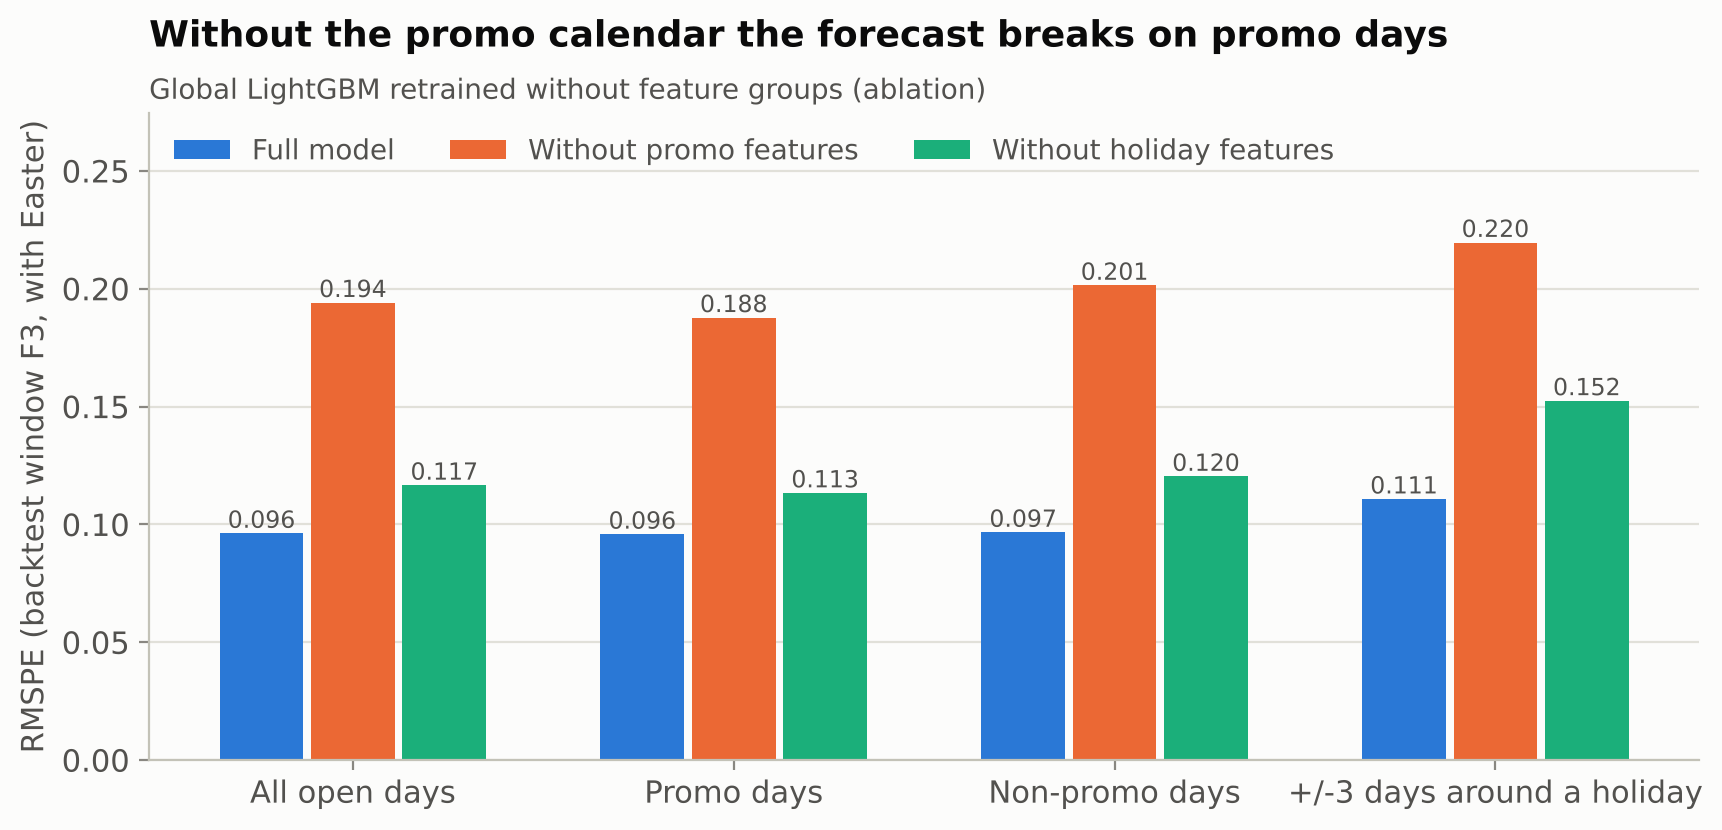

In [9]:
ab = pd.read_csv(MET_DIR / "ablation.csv")
display(ab.pivot_table(index="segment", columns="variant", values="RMSPE").round(4))
display(Image(FIG_DIR / "fig09_ablation.png", width=850))

## 4. Correlation with external factors
Spearman correlation between each external factor and daily log sales of open store-days, with each store's mean
removed (otherwise store size dominates every correlation). Weather is not part of the Kaggle data; the factors
available are holidays, school holidays, promotions and competition.

,factor,share_of_days_pct,spearman_sales,spearman_sales_within_weekday,spearman_customers
0,Promo day,44.6360,0.6770,0.6510,0.5560
5,Christmas week (18-23 Dec),1.2200,0.1560,0.1740,0.1510
3,Day after a state holiday,3.3840,0.0800,0.1090,0.1080
2,Day before a state holiday,2.4720,0.0700,0.0840,0.0880
1,School holiday,19.3580,0.0530,-0.0050,0.0410
7,Competitor open,91.6980,-0.0160,-0.0160,-0.0330
6,Promo2 coupon month,14.9540,-0.0070,-0.0060,-0.0160
4,Open on a state holiday,0.1080,0.0050,0.0030,-0.0010


,factor,spearman_mean_sales,n_stores
0,Log distance to nearest competitor,-0.0280,1115
1,Months since competitor opened,-0.0740,761
2,Takes part in Promo2,-0.1460,1115
3,Extended assortment (c),0.1580,1115
4,Store type b,0.0970,1115
5,Share of Sundays open,0.0650,1115


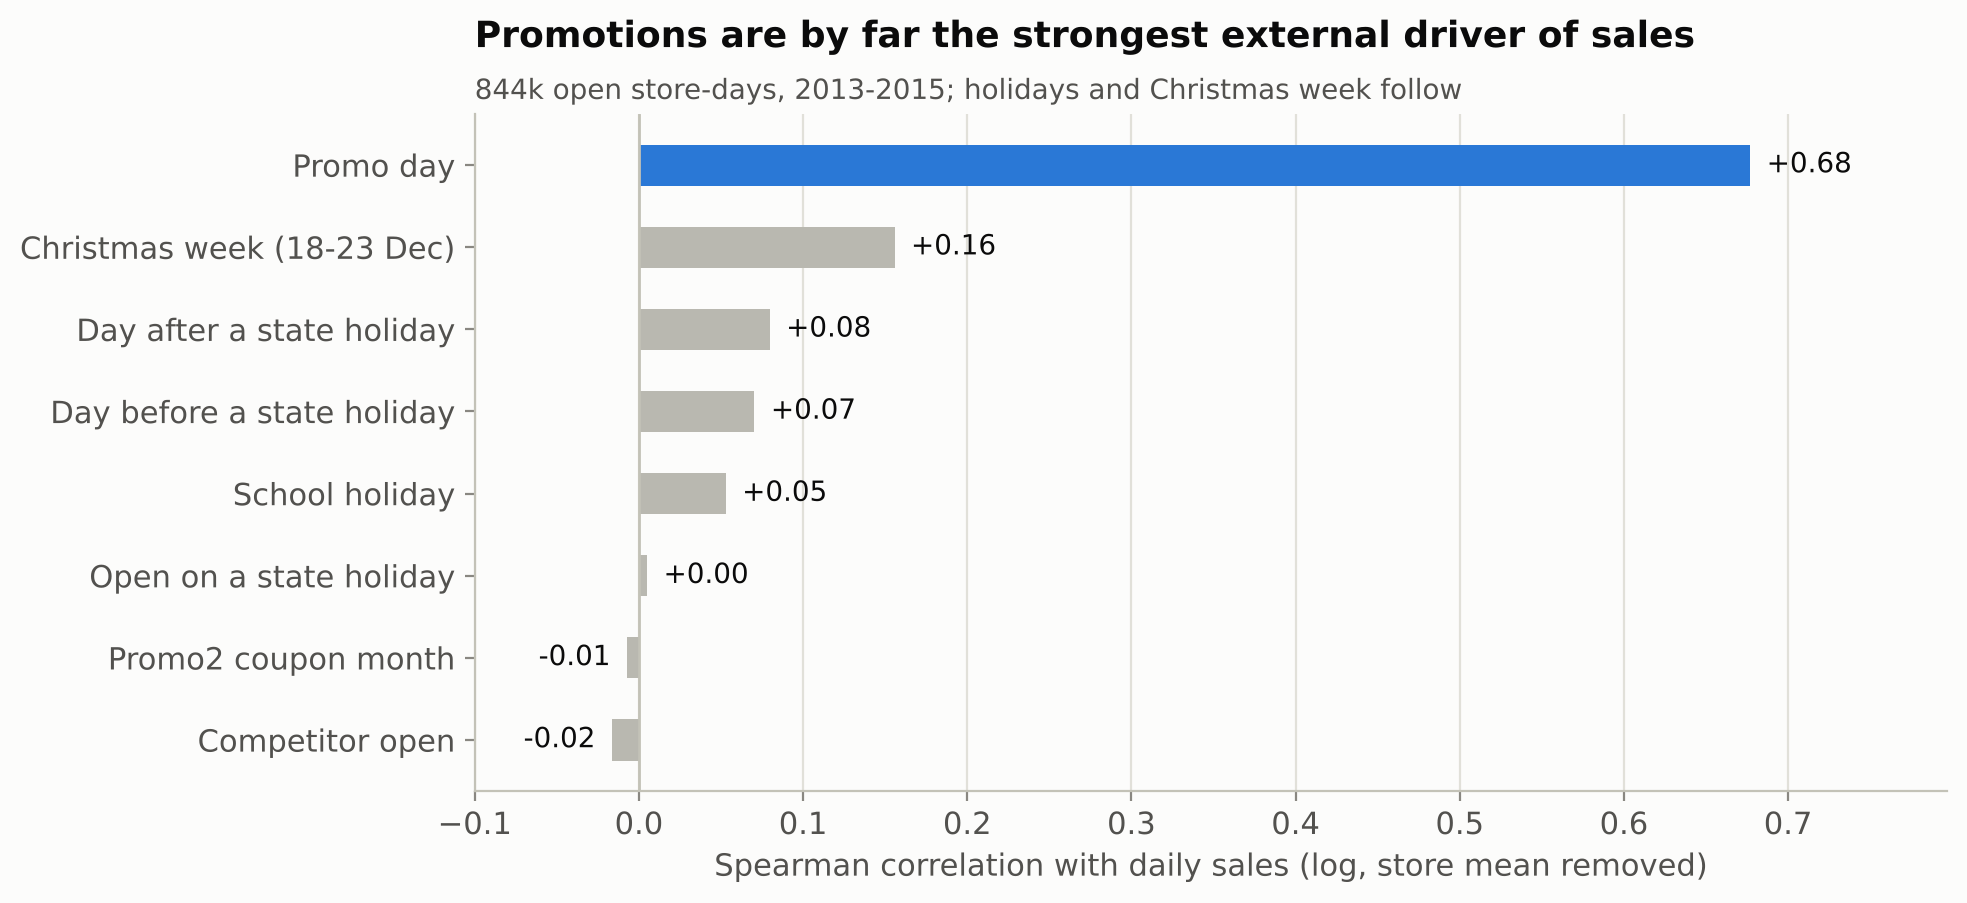

Interactive correlation matrix: outputs/figures/interactive_correlations.html


,Sales (vs store mean),Customers (vs store mean),Promo day,School holiday,Day before a state holiday,Day after a state holiday,Open on a state holiday,Christmas week (18-23 Dec),Promo2 coupon month,Competitor open
Sales (vs store mean),1.0000,0.9400,0.6800,0.0500,0.0700,0.0800,0.0100,0.1500,-0.0000,-0.0200
Customers (vs store mean),0.9400,1.0000,0.5600,0.0400,0.0900,0.1100,0.0000,0.1500,-0.0100,-0.0300
Promo day,0.6800,0.5600,1.0000,0.0300,0.0200,-0.0900,0.0000,0.0200,0.0100,0.0000
School holiday,0.0500,0.0400,0.0300,1.0000,0.1000,0.1200,0.0100,0.0300,0.0200,-0.0000
Day before a state holiday,0.0700,0.0900,0.0200,0.1000,1.0000,-0.0300,-0.0100,-0.0200,0.0100,0.0000
Day after a state holiday,0.0800,0.1100,-0.0900,0.1200,-0.0300,1.0000,-0.0100,-0.0200,0.0100,0.0000
Open on a state holiday,0.0100,0.0000,0.0000,0.0100,-0.0100,-0.0100,1.0000,-0.0000,-0.0100,0.0000
Christmas week (18-23 Dec),0.1500,0.1500,0.0200,0.0300,-0.0200,-0.0200,-0.0000,1.0000,-0.0200,0.0100
Promo2 coupon month,-0.0000,-0.0100,0.0100,0.0200,0.0100,0.0100,-0.0100,-0.0200,1.0000,0.0500
Competitor open,-0.0200,-0.0300,0.0000,-0.0000,0.0000,0.0000,0.0000,0.0100,0.0500,1.0000


In [10]:
corr = E.correlations(panel)
display(corr["store_day"].round(3))
display(corr["store_level"].round(3))
display(Image(FIG_DIR / "fig14_correlations.png", width=850))
print("Interactive correlation matrix: outputs/figures/interactive_correlations.html")
corr["matrix"].round(2)

## 5. Findings
* **Promo**: +37.9% sales on a promo day (95% CI 36.2–39.7%) = +20.0% customers × +14.9% sales per customer. Largest on Monday (+62%), smallest on Friday (+22%) and in type b stores (+12%).
* **Model-based check**: turning promo weeks into regular weeks in the global LightGBM forecast gives +36.8% — the two methods agree. Switching off only the promo flag gives +24.1%, because that feature combination never occurs in training.
* **State holidays**: only 2–3% of stores open; demand moves to the day before (+19%) and after (+23%).
* **Christmas**: up to +69% on 23 December; Christmas Eve −27%, New Year's Eve −50%.
* **School holidays** +1.1%, **Promo2 coupon months** −0.3% (not significant).
* **Ablation**: without promo features the error doubles (0.096 → 0.194 on F3); without holiday features it rises 38% on days near holidays.
* **Correlations**: promo days correlate most with sales (Spearman +0.68 with store-demeaned log sales), then Christmas week (+0.16) and the days next to state holidays (+0.07 to +0.08); school holidays, Promo2 months and competitor openings are near zero.